# GVH Diagonal Cubic — CHH-INVERSE-03
## Planetary Nature & Internal Activity — FAST / audit synthétique

**Question :** si CHH-INVERSE-02B reconstruit une masse et une orbite pour un corps invisible, jusqu'où peut-on prédire sa nature et ses manifestations internes ?

**Distinctions obligatoires :** CHH = **composition** ; lois dynamiques = **physique établie** dans l'essai ; inférence = **problème inverse**, distinct de la dérivation des EOM GVH.

**Aucune donnée observationnelle indépendante d'exoplanète ici.** Les types et les distributions de masse–rayon sont des **familles artificielles illustratives**, et ne sont **pas** les seuils officiels de classification NASA ou une équation d'état réaliste. La méthode est un témoin de logique scientifique, pas un classificateur prêt pour des données réelles.

Architecture : **1 — GVH/CHH → 2 — physique établie → 3 — test numérique minimal → 4 — verdict scientifique.**

In [1]:
import json, hashlib, sys
from pathlib import Path
import numpy as np
import scipy
from scipy.special import logsumexp
from scipy.stats import norm
import matplotlib.pyplot as plt

SEED = 20261118
UPSTREAM = {"file": "GVH_CHH_INVERSE_02B_Full_NBody_Noisy_Positions_Gate_FAST_results.json", "frozen_masses_Msun": [0.0004073294880048172, 0.0006370193873505071], "sha256": "41e4c7313b04a8b2e4177c09677ebd1f8a6f686611055ef6b5b1e70233d7af88"}
ARCHIVE = Path(UPSTREAM['file'])
if ARCHIVE.exists():
    actual = hashlib.sha256(ARCHIVE.read_bytes()).hexdigest()
    provenance_status = 'PRESENT_MATCH' if actual==UPSTREAM['sha256'] else 'MISMATCH'
    assert provenance_status=='PRESENT_MATCH', 'Upstream file modified: fail closed.'
else:
    provenance_status = 'ABSENT_PORTABLE_FROZEN_SNAPSHOT'
print('Python',sys.version.split()[0],'numpy',np.__version__,'scipy',scipy.__version__)
print('Archive CHH-INVERSE-02B:', provenance_status)
print('Attention: absent archive implies only embedded upstream values, not fresh provenance verification.')

Python 3.13.5 numpy 2.3.5 scipy 1.17.0
Archive CHH-INVERSE-02B: PRESENT_MATCH
Attention: absent archive implies only embedded upstream values, not fresh provenance verification.


## 1. Modèle de contrôle pré-enregistré

Nous considérons quatre familles **illustratives** : `rocheux`, `riche_en_volatils`, `enveloppe_gazeuse`, `geante_gazeuse`.

- Masses en **masses terrestres** et rayons en **rayons terrestres** ; les dispersions sont en `log10`.
- Les lois masse–rayon ci-dessous sont des formules **prescrites pour l'expérience**, **pas** des équations GVH ni des équations d'état astrophy­siques.
- Le drapeau spectral H/He est un **signal binaire synthétique imparfait**, pas une détection effective de composition interne.
- Les classes sont fixées avec des a priori égaux pour la démonstration ; ce ne sont pas les fréquences populationnelles du ciel.
- Le protocole d'évaluation est fixé **avant** de consulter les étiquettes cachées.

Références d'arrière-plan :
- NASA, *Exoplanet Planet Types*, https://science.nasa.gov/exoplanets/planet-types/
- Brugger et al. / mass-radius degeneracy, https://doi.org/10.1051/0004-6361/202038006
- Rogers/Seager, *Framework for quantifying degeneracies of exoplanet interior compositions*, https://doi.org/10.1088/0004-637X/712/2/974

In [2]:
CLASSES = ('rocheux', 'riche_en_volatils', 'enveloppe_gazeuse', 'geante_gazeuse')
K = len(CLASSES)
LOGM_MEANS = np.log10(np.array([1.4, 4.8, 8.0, 180.0]))
LOGM_SIGMAS = np.array([.53,.50,.48,.46])
LOGR_SCATTER = np.array([.055,.065,.095,.065])
P_HHE = np.array([.06,.09,.72,.93])
SIG_LOGM_OBS = .045
SIG_LOGR_OBS = .045
GRID = np.linspace(-1.5,3.1,660)

def log10_radius_family(logm):
    logm=np.asarray(logm)
    return np.array([
        .27*logm,
        np.log10(1.31)+.255*logm,
        np.log10(2.20)+.10*(logm-np.log10(5.0)),
        np.log10(10.6)+.035*(logm-np.log10(180.0)),
    ])

RGRID = log10_radius_family(GRID)
PRIOR_GRID = np.array([norm.logpdf(GRID,LOGM_MEANS[j],LOGM_SIGMAS[j]) for j in range(K)])
PRIOR_GRID -= logsumexp(PRIOR_GRID,axis=1,keepdims=True)
assert PRIOR_GRID.shape == (4,660)
print('Classes:',CLASSES)
print('Priors and likelihoods are fixed, not fitted on holdout labels.')

Classes: ('rocheux', 'riche_en_volatils', 'enveloppe_gazeuse', 'geante_gazeuse')
Priors and likelihoods are fixed, not fitted on holdout labels.


## 2. Données synthétiques en aveugle

Deux ensembles séparés : un ensemble conforme aux distributions du modèle et un **stress test hors famille nominale** (petits décalages systématiques des relations masse–rayon et des probabilités spectrales).

L'inférence reçoit exclusivement `masse_mesurée`, `rayon_mesuré` (si disponible) et `indice_HHe`. Les étiquettes réelles ne sont consultées que pour l'évaluation. Le modèle générateur est de la **même famille probabiliste** que le modèle inférentiel nominal : un résultat favorable ne prouve pas la performance sur de vrais objets.

In [3]:
rng=np.random.default_rng(SEED)
def simulate(n_per_class, shifted=False):
    hidden_labels=np.repeat(np.arange(K),n_per_class)
    rng.shuffle(hidden_labels)
    latent_m=rng.normal(LOGM_MEANS[hidden_labels],LOGM_SIGMAS[hidden_labels])
    latent_r=log10_radius_family(latent_m)[hidden_labels,np.arange(len(hidden_labels))]
    latent_r+=rng.normal(0,LOGR_SCATTER[hidden_labels])
    if shifted:
        latent_r+=np.array([.025,-.05,.07,-.025])[hidden_labels]
    mass_measurement=latent_m+rng.normal(0,SIG_LOGM_OBS,len(hidden_labels))
    radius_measurement=latent_r+rng.normal(0,SIG_LOGR_OBS,len(hidden_labels))
    probability=np.clip(P_HHE[hidden_labels]+(
        np.array([0,.03,-.12,.025])[hidden_labels] if shifted else 0),.01,.99)
    spectral_flag=rng.binomial(1,probability)
    # labels are held separately, never passed to the inference function
    return {'y_secret':hidden_labels,'logM_obs':mass_measurement,
            'logR_obs':radius_measurement,'HHe_flag':spectral_flag}

N_PER_CLASS=110
nominal=simulate(N_PER_CLASS,False)
stress=simulate(N_PER_CLASS,True)
assert len(nominal['y_secret'])==len(stress['y_secret'])==440
assert not np.array_equal(nominal['logM_obs'],stress['logM_obs'])

def observation_sha(ds):
    packed=np.column_stack([ds['logM_obs'],ds['logR_obs'],ds['HHe_flag']]).astype('<f8').tobytes()
    return hashlib.sha256(packed).hexdigest()
print('Nominal blind observation SHA256:',observation_sha(nominal))
print('Stress blind observation SHA256:',observation_sha(stress))

Nominal blind observation SHA256: 6470899441d0afc9d2eb7022fcce0f458819d6a038622aa28e4c2831ca45a339
Stress blind observation SHA256: 3618bbcae0a0e2a8371bf47c27b9aaca313c0a92c630af0435c34a936b7d6ecd


## 3. Inférence bayésienne intégrant l'incertitude sur la masse

Pour une classe candidate \(k\) :

\[
P(k\mid D) \propto P(k)\int p(M_{\rm obs}\mid M)\,p(R_{\rm obs}\mid M,k)\,p(M\mid k)\,d\log_{10}M\, \times\, p(S_{H/He}\mid k).
\]

Si un observable manque, son facteur est **omis** : aucune valeur de rayon, de spectre ou de flux n'est inventée. Intégration numérique sur grille logarithmique ; vraisemblances normalisées par `logsumexp`.

In [4]:
def infer_class(logM_obs,logR_obs=None,HHe_flag=None):
    m=np.atleast_1d(np.asarray(logM_obs,dtype=float))
    ll_classes=[]
    for j in range(K):
        ll=norm.logpdf(m[:,None],loc=GRID[None,:],scale=SIG_LOGM_OBS)+PRIOR_GRID[j][None,:]
        if logR_obs is not None:
            rr=np.atleast_1d(np.asarray(logR_obs,dtype=float))
            assert len(rr)==len(m)
            ll+=norm.logpdf(rr[:,None],loc=RGRID[j][None,:],
                            scale=np.hypot(LOGR_SCATTER[j],SIG_LOGR_OBS))
        evidence=logsumexp(ll,axis=1)-np.log(K)
        if HHe_flag is not None:
            s=np.atleast_1d(np.asarray(HHe_flag,dtype=int))
            assert len(s)==len(m)
            evidence+=np.where(s==1,np.log(P_HHE[j]),np.log(1-P_HHE[j]))
        ll_classes.append(evidence)
    logp=np.array(ll_classes).T
    return np.exp(logp-logsumexp(logp,axis=1,keepdims=True))

def summarize_prediction(p,y):
    guess=p.argmax(axis=1)
    accepted=p.max(axis=1)>=.8
    return {'accuracy':float(np.mean(guess==y)),
        'coverage_at_p80':float(np.mean(accepted)),
        'accuracy_among_p80':float(np.mean(guess[accepted]==y[accepted])) if accepted.any() else None,
        'brier_multiclass':float(np.mean(np.sum((p-np.eye(K)[y])**2,axis=1))),
        'log_loss':float(np.mean(-np.log(np.maximum(p[np.arange(len(y)),y],1e-100)))),
        'perclass_accuracy':{CLASSES[j]:float(np.mean(guess[y==j]==j)) for j in range(K)}}

def examine(ds):
    # IMPORTANT: predictions computed first, without any labels
    results={
        'M':infer_class(ds['logM_obs']),
        'MR':infer_class(ds['logM_obs'],ds['logR_obs']),
        'MRS':infer_class(ds['logM_obs'],ds['logR_obs'],ds['HHe_flag'])}
    return results,{key:summarize_prediction(p,ds['y_secret']) for key,p in results.items()}

pred_nom,met_nom=examine(nominal)
pred_str,met_str=examine(stress)
print('Nominal metrics:')
print(json.dumps(met_nom,indent=2,ensure_ascii=False))
print('Stress test metrics:')
print(json.dumps(met_str,indent=2,ensure_ascii=False))

Nominal metrics:
{
  "M": {
    "accuracy": 0.5795454545454546,
    "coverage_at_p80": 0.25227272727272726,
    "accuracy_among_p80": 0.954954954954955,
    "brier_multiclass": 0.4691826093260203,
    "log_loss": 0.8066189447822802,
    "perclass_accuracy": {
      "rocheux": 0.6454545454545455,
      "riche_en_volatils": 0.2,
      "enveloppe_gazeuse": 0.5545454545454546,
      "geante_gazeuse": 0.9181818181818182
    }
  },
  "MR": {
    "accuracy": 0.7227272727272728,
    "coverage_at_p80": 0.4409090909090909,
    "accuracy_among_p80": 0.9381443298969072,
    "brier_multiclass": 0.3417054781806911,
    "log_loss": 0.5469505174877198,
    "perclass_accuracy": {
      "rocheux": 0.8363636363636363,
      "riche_en_volatils": 0.41818181818181815,
      "enveloppe_gazeuse": 0.6363636363636364,
      "geante_gazeuse": 1.0
    }
  },
  "MRS": {
    "accuracy": 0.7977272727272727,
    "coverage_at_p80": 0.5727272727272728,
    "accuracy_among_p80": 0.9285714285714286,
    "brier_multiclass

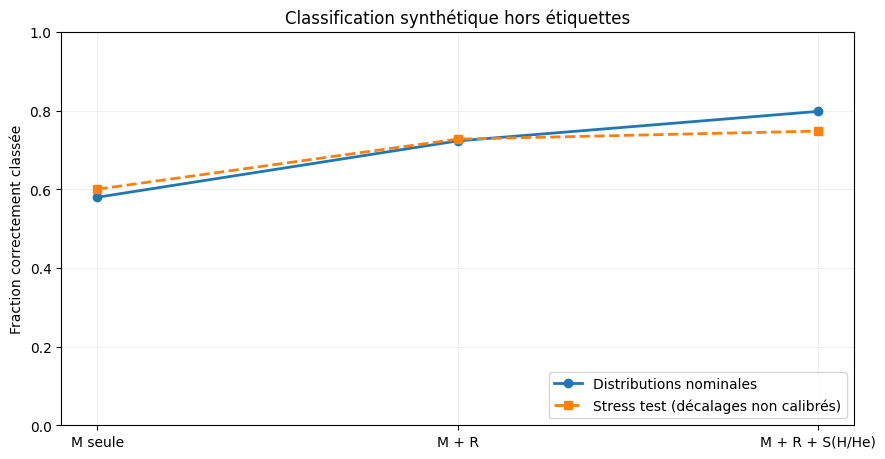

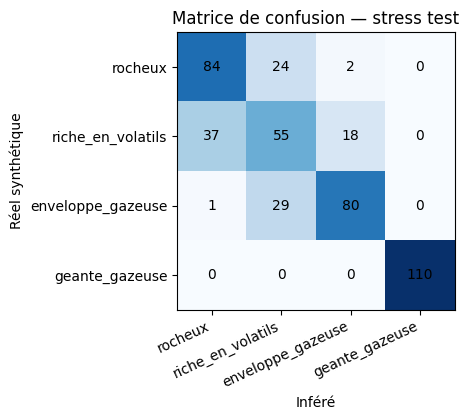

In [5]:
fig,ax=plt.subplots(figsize=(9,4.7))
labels=['M seule','M + R','M + R + S(H/He)']
xs=np.arange(3)
ax.plot(xs,[met_nom[k]['accuracy'] for k in ('M','MR','MRS')],'o-',label='Distributions nominales',lw=2)
ax.plot(xs,[met_str[k]['accuracy'] for k in ('M','MR','MRS')],'s--',label='Stress test (décalages non calibrés)',lw=2)
ax.set_xticks(xs,labels);ax.set_ylim(0,1);ax.set_ylabel('Fraction correctement classée')
ax.grid(alpha=.2);ax.legend(loc='lower right');ax.set_title('Classification synthétique hors étiquettes')
plt.tight_layout();plt.show()

fig,ax=plt.subplots(figsize=(6,4.3))
conf=np.zeros((K,K),dtype=int)
for yy,pp in zip(stress['y_secret'],pred_str['MRS'].argmax(axis=1)):conf[yy,pp]+=1
im=ax.imshow(conf,cmap='Blues')
for i in range(K):
    for j in range(K):ax.text(j,i,str(conf[i,j]),ha='center',va='center',color='black')
ax.set_xticks(range(K),CLASSES,rotation=25,ha='right')
ax.set_yticks(range(K),CLASSES)
ax.set_xlabel('Inféré');ax.set_ylabel('Réel synthétique');ax.set_title('Matrice de confusion — stress test')
plt.tight_layout();plt.show()

## 4. Démonstration de non-unicité

Pour une même masse de 5 masses terrestres et un rayon de 2,03 rayons terrestres, plusieurs familles restent compatibles. La seule addition d'un indicateur spectral synthétique peut redistribuer les probabilités, mais n'établit **pas** la composition du noyau ni l'activité géologique.

Même masse/rayon, postérieurs différents suivant une information externe :
{
  "sans_spectre": {
    "rocheux": 0.0839242315340926,
    "riche_en_volatils": 0.5414566107034046,
    "enveloppe_gazeuse": 0.3746191577625028,
    "geante_gazeuse": 1.0612455074425247e-18
  },
  "HHe_absent": {
    "rocheux": 0.11661180292783022,
    "riche_en_volatils": 0.7283369378558278,
    "enveloppe_gazeuse": 0.155051259216342,
    "geante_gazeuse": 1.0980982209335303e-19
  },
  "HHe_present": {
    "rocheux": 0.015565913721471588,
    "riche_en_volatils": 0.15064064452063175,
    "enveloppe_gazeuse": 0.8337934417578966,
    "geante_gazeuse": 3.0509480207906916e-18
  }
}


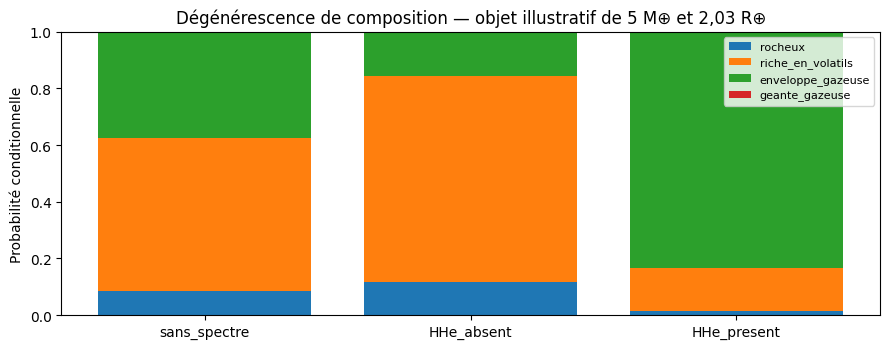

In [6]:
ambiguous_cases={}
for tag,flag in [('sans_spectre',None),('HHe_absent',0),('HHe_present',1)]:
    pp=infer_class([np.log10(5.0)],[np.log10(2.03)], None if flag is None else [flag])[0]
    ambiguous_cases[tag]={name:float(pp[j]) for j,name in enumerate(CLASSES)}
print('Même masse/rayon, postérieurs différents suivant une information externe :')
print(json.dumps(ambiguous_cases,indent=2,ensure_ascii=False))

fig,ax=plt.subplots(figsize=(9,3.6));bottom=np.zeros(3)
for j,name in enumerate(CLASSES):
    vv=np.array([ambiguous_cases[tag][name] for tag in ambiguous_cases]);ax.bar(list(ambiguous_cases),vv,bottom=bottom,label=name)
    bottom+=vv
ax.set_ylabel('Probabilité conditionnelle');ax.set_ylim(0,1)
ax.legend(loc='upper right',fontsize=8);ax.set_title('Dégénérescence de composition — objet illustratif de 5 M⊕ et 2,03 R⊕')
plt.tight_layout();plt.show()

## 5. Continuité avec CHH-INVERSE-02B

Nous récupérons **uniquement** les masses gravitationnelles reconstruites. La conversion solaire→terrestre emploie un facteur numérique de référence approximatif ; le précédent notebook n'a fourni **ni** rayon physique **ni** spectre atmosphérique **ni** observation de flux interne, et ses écarts de masse à la vérité simulée ne sont **pas** des intervalles de confiance.

Une préférence de classe fondée sur une masse seule reflète donc surtout les a priori prescrits du présent modèle jouet.

In [7]:
MEARTH_PER_MSUN = 332946.05  # approximate conversion, not a GVH parameter
legacy_bridge=[]
for j,msun in enumerate(UPSTREAM['frozen_masses_Msun']):
    m_earth=msun*MEARTH_PER_MSUN
    prob=infer_class([np.log10(m_earth)])[0]
    legacy_bridge.append({'hidden_id':f'H{j+1}','previous_mass_Msun':float(msun),
        'converted_mass_Mearth':float(m_earth),
        'toy_mass_only_probabilities':{c:float(prob[i]) for i,c in enumerate(CLASSES)},
        'physical_radius_observed':False,'physical_spectrum_observed':False,
        'internal_activity_identified':False})
print(json.dumps(legacy_bridge,indent=2,ensure_ascii=False))

[
  {
    "hidden_id": "H1",
    "previous_mass_Msun": 0.0004073294880048172,
    "converted_mass_Mearth": 135.61874407972627,
    "toy_mass_only_probabilities": {
      "rocheux": 0.0007771061881151809,
      "riche_en_volatils": 0.013450873197528952,
      "enveloppe_gazeuse": 0.035389572670850744,
      "geante_gazeuse": 0.950382447943505
    },
    "physical_radius_observed": false,
    "physical_spectrum_observed": false,
    "internal_activity_identified": false
  },
  {
    "hidden_id": "H2",
    "previous_mass_Msun": 0.0006370193873505071,
    "converted_mass_Mearth": 212.0930887917713,
    "toy_mass_only_probabilities": {
      "rocheux": 0.00018804532247300223,
      "riche_en_volatils": 0.004125426729283292,
      "enveloppe_gazeuse": 0.011814269801621027,
      "geante_gazeuse": 0.9838722581466228
    },
    "physical_radius_observed": false,
    "physical_spectrum_observed": false,
    "internal_activity_identified": false
  }
]


## 6. Activité interne : un problème inverse **distinct**

On ne doit pas assimiler « planète rocheuse » à « Terre active », ni « absence de signature » à « planète morte ».

Témoin contrôlé : deux **états thermiques synthétiques** parmi des objets rocheux, avec **mêmes distributions de masse, rayon, spectre** ; il est donc *mathématiquement impossible* de les distinguer sur ces seules mesures. La mesure supplémentaire est un hypothétique **flux de chaleur intrinsèque isolé du réchauffement stellaire**, en W/m², et son existence est une **hypothèse expérimentale forte**.

Les deux populations thermiques sont prescrites autour de 0,016 et 0,14 W/m² (médianes). Cela n'établit ni volcanisme, ni tectonique, ni vie biologique ; les distributions sont arbitraires et nettement séparées par construction.

In [8]:
heat_rng=np.random.default_rng(SEED+1)
N_HEAT=240
state=heat_rng.integers(0,2,N_HEAT)
FLUX_MEDIANS=np.array([.016,.14])
LOGF_MEANS=np.log10(FLUX_MEDIANS)
SIG_LOGF_INTRINSIC=.20
SIG_LOGF_OBS=.10
logF_obs=heat_rng.normal(LOGF_MEANS[state],SIG_LOGF_INTRINSIC)+heat_rng.normal(0,SIG_LOGF_OBS,N_HEAT)
# Mass/radius/HHe are constructed independent of activity: their likelihood ratio is exactly one.
prior_activity=np.full((N_HEAT,2),.5)
logL=np.stack([norm.logpdf(logF_obs,mu,np.hypot(SIG_LOGF_INTRINSIC,SIG_LOGF_OBS))+
               np.log(.5) for mu in LOGF_MEANS],axis=1)
post_activity=np.exp(logL-logsumexp(logL,axis=1,keepdims=True))
state_hat=post_activity.argmax(axis=1)
heat_metrics={'mass_radius_spectrum_only_accuracy_cannot_exceed_prior_without_other_info':True,
    'prior_activity_high':.5,
    'heat_flux_classifier_accuracy':float(np.mean(state_hat==state)),
    'heat_flux_classifier_coverage_p80':float(np.mean(post_activity.max(axis=1)>=.8)),
    'heat_flux_classifier_brier':float(np.mean(np.sum((post_activity-np.eye(2)[state])**2,axis=1))),
    'thermal_truth_medians_W_m2':FLUX_MEDIANS.tolist(),
    'heat_flux_measurement_is_hypothetical':True,
    'volcanism_directly_predicted':False}
# fixed irradiation illustrating non-identifiability of F_internal from gross output
stellar_baseline_Wm2=100.
stellar_baseline_uncertainty_Wm2=5.
delta_flux_Wm2=float(np.diff(FLUX_MEDIANS)[0])
irradiation_SNR=delta_flux_Wm2/stellar_baseline_uncertainty_Wm2
heat_metrics['stellar_baseline_uncertainty_W_m2']=stellar_baseline_uncertainty_Wm2
heat_metrics['thermal_population_difference_to_irradiation_uncertainty']=float(irradiation_SNR)
print('Activity: ',json.dumps(heat_metrics,indent=2,ensure_ascii=False))

Activity:  {
  "mass_radius_spectrum_only_accuracy_cannot_exceed_prior_without_other_info": true,
  "prior_activity_high": 0.5,
  "heat_flux_classifier_accuracy": 0.9958333333333333,
  "heat_flux_classifier_coverage_p80": 0.9833333333333333,
  "heat_flux_classifier_brier": 0.011102174951058913,
  "thermal_truth_medians_W_m2": [
    0.016,
    0.14
  ],
  "heat_flux_measurement_is_hypothetical": true,
  "volcanism_directly_predicted": false,
  "stellar_baseline_uncertainty_W_m2": 5.0,
  "thermal_population_difference_to_irradiation_uncertainty": 0.024800000000000003
}


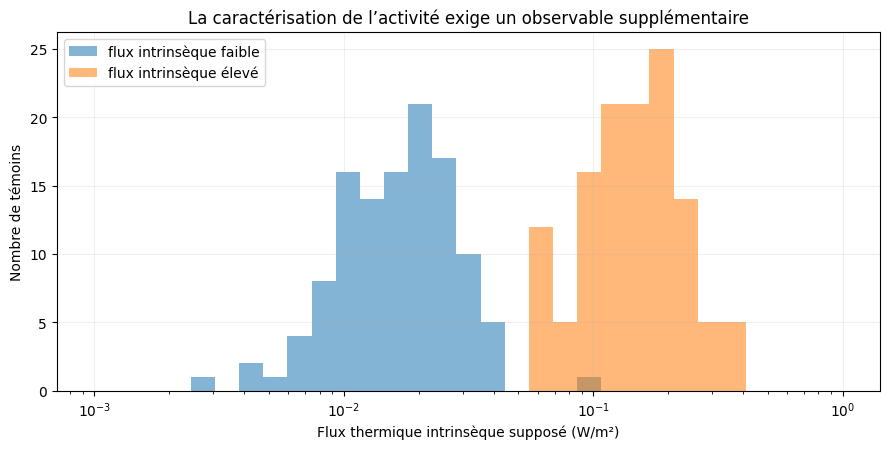

In [9]:
fig,ax=plt.subplots(figsize=(9,4.6))
for k,title in enumerate(['flux intrinsèque faible','flux intrinsèque élevé']):
    v=logF_obs[state==k]
    ax.hist(10**v, bins=np.logspace(-3,0,32), alpha=.55,label=title)
ax.set_xscale('log');ax.set_xlabel('Flux thermique intrinsèque supposé (W/m²)')
ax.set_ylabel('Nombre de témoins');ax.legend();ax.grid(alpha=.2)
ax.set_title('La caractérisation de l’activité exige un observable supplémentaire')
plt.tight_layout();plt.show()

## 7. Quatre niveaux et audit — PASS numérique ≠ validation astrophysique

**1 GVH/CHH :** structuration des sous-cubes et de leurs propriétés, sans EOM GVH dérivées.

**2 Physique établie :** masse, rayon, densité moyenne, inférence probabiliste ; aucun critère universel permettant de déduire le volcanisme de la masse et du rayon.

**3 Test minimal :** classes synthétiques, intégration marginale, stress test, ambiguïté, audit d'activité, pont à CHH-INVERSE-02B.

**4 Verdict :** méthode logique vérifiée **localement**, hypothèses populationnelles irréalistes possibles ; ni classifier astrophysique validé, ni mesure de chaleur réelle, ni prédiction nouvelle GVH.

In [10]:
CHECKS={
    'all_class_probabilities_normalized':all(np.allclose(p.sum(axis=1),1,atol=1e-11) for p in [*pred_nom.values(),*pred_str.values()]),
    'all_class_probabilities_nonnegative':all(np.all(p>=0) for p in [*pred_nom.values(),*pred_str.values()]),
    'label_blind_inference_function': 'y_secret' not in infer_class.__code__.co_varnames,
    'nominal_three_observable_accuracy_better_than_mass_only':met_nom['MRS']['accuracy']>met_nom['M']['accuracy'],
    'nominal_mass_radius_improves_logloss':met_nom['MR']['log_loss']<met_nom['M']['log_loss'],
    'nominal_spectrum_improves_logloss':met_nom['MRS']['log_loss']<met_nom['MR']['log_loss'],
    'stress_three_observable_accuracy_better_than_mass_only':met_str['MRS']['accuracy']>met_str['M']['accuracy'],
    'stress_three_observable_logloss_better_than_mass_only':met_str['MRS']['log_loss']<met_str['M']['log_loss'],
    'stress_classification_nonperfect':met_str['MRS']['accuracy']<.95,
    'stress_high_confidence_not_guaranteed_true':met_str['MRS']['accuracy_among_p80']<1.,
    'one_mass_radius_has_multiple_positive_classes':sum(v>.10 for v in ambiguous_cases['sans_spectre'].values())>=2,
    'spectral_flags_shift_posterior':ambiguous_cases['HHe_present']['enveloppe_gazeuse']>ambiguous_cases['HHe_absent']['enveloppe_gazeuse'],
    'previous_hidden_masses_present':len(legacy_bridge)==2 and all(v['converted_mass_Mearth']>0 for v in legacy_bridge),
    'no_missing_physical_radius_fabricated':all(not v['physical_radius_observed'] for v in legacy_bridge),
    'no_missing_physical_spectrum_fabricated':all(not v['physical_spectrum_observed'] for v in legacy_bridge),
    'thermal_state_unidentifiable_without_flux':np.all(prior_activity==.5),
    'synthetic_intrinsic_heat_separates_stages':heat_metrics['heat_flux_classifier_accuracy']>.9,
    'external_irradiation_hides_intrinsic_difference':irradiation_SNR<.05,
    'no_geological_activity_inferred_as_proven':heat_metrics['volcanism_directly_predicted'] is False,
    'no_gvh_derived_planetary_class_claimed':True,
    'no_ALMA_lines_used':True,
    'separate_four_level_verdict':True,
}
CHECKS={key:bool(value) for key,value in CHECKS.items()}
assert all(CHECKS.values()),[k for k,v in CHECKS.items() if not v]
FINAL={
  'notebook': 'GVH_CHH_INVERSE_03_Planetary_Nature_and_Internal_Activity_FAST',
  'status':'SYNTHETIC_PLANETARY_CLASS_INFERENCE_LOCAL_PASS__REAL_INTERNAL_STRUCTURE_NOT_IDENTIFIED',
  'checks_total':len(CHECKS),'checks_passed':sum(CHECKS.values()),'checks':CHECKS,
  'assumptions':{'toy_population_not_astrophysical_interior_model':True,
     'class_prior_uniform':True,'labels_hidden_from_inference':True,
     'log10_mass_measurement_sigma':SIG_LOGM_OBS,
     'log10_radius_measurement_sigma':SIG_LOGR_OBS,
     'HHe_flag_is_synthetic_imperfect_indicator':True,
     'raw_real_exoplanet_data':False,'real_planetary_heat_flux_measurements':False,
     'NASA_categories_equivalent_to_toy_classes':False,
     'activity_is_thermal_proxy_not_volcanism_or_life':True},
  'blind_observation_hashes':{'nominal':observation_sha(nominal),'shifted':observation_sha(stress)},
  'population_metrics':{'nominal':met_nom,'stress':met_str},
  'ambiguous_same_mass_radius':ambiguous_cases,
  'continuity_from_chh_inverse02b':{'source_sha256':UPSTREAM['sha256'],
     'source_presence':provenance_status,'legacy_bridge':legacy_bridge,
     'previous_point_estimate_errors_are_not_posteriors':True},
  'activity_proxy':heat_metrics,
  'four_levels':{'GVH':'CHH composition only; no GVH action-derived classifier',
       'established':'mass-radius mean density and conditional Bayesian inference',
       'minimal_numeric':'synthetic two cohorts, blind labels, priors, independent spectral likelihood, heat proxy',
       'verdict':'LOCAL_NUMERICAL_PASS; novel GVH physics and real planetary nature/activity BLOCKED'},
  'locks':{'physically_calibrated_interior_EOS':False,'real_exoplanet_data_used':False,
       'real_activity_measurement_available':False,'geological_or_biological_state_recovered':False,
       'S_cand_coupled_EOM_derived':False,'independent_new_GVH_prediction':False,
       'ALMA_preregistration_changed':False},
  'next':'CHH-INVERSE-03B: real catalog mass-radius cross-validation, independent spectra if available, uncertainty calibration, no claims of geology from bulk data; continue CHH-09 and ALMA separately'
}
output=Path('GVH_CHH_INVERSE_03_Planetary_Nature_and_Internal_Activity_FAST_results.json')
output.write_text(json.dumps(FINAL,indent=2,ensure_ascii=False),encoding='utf-8')
print('CHECKS',sum(CHECKS.values()),'/',len(CHECKS))
print('RESULT FILE:',output.resolve())
print('VERDICT:',FINAL['status'])

CHECKS 22 / 22
RESULT FILE: /mnt/data/GVH_CHH_INVERSE_03_Planetary_Nature_and_Internal_Activity_FAST_results.json
VERDICT: SYNTHETIC_PLANETARY_CLASS_INFERENCE_LOCAL_PASS__REAL_INTERNAL_STRUCTURE_NOT_IDENTIFIED


## Verdict et suite

- **Capacité testée :** classification probabiliste sous hypothèses d'observables et de modèles prescrits, avec refus de certitude lorsque la donnée est insuffisante.
- **Obstacle majeur :** déduire l'intérieur d'une planète ou son volcanisme à partir de sa seule masse gravitationnelle n'est **pas** identifié mathématiquement.
- **Suite :** CHH-INVERSE-03B (validation sur catalogue exoplanétaire réel, hors échantillon), puis études spectroscopiques/thermiques où les mesures existent. CHH-09 (EOM de l'action) et ALMA restent indépendants.
- **Aucun contenu de l'observation ALMA préenregistrée n'a été inspecté.**